---
# <font color="#CA3532">Deep Learning Fundamentals and Basic Tools (2026/2027) - Final project</font>
---


In this project you will implement and compare four deep-learning architectures for multiclass human activity recognition:

- Deep Neural Network (DNN)
- Recurrent Neural Network (RNN)
- 1D Convolutional Neural Network (CNN)
- Long Short-Term Memory Network (LSTM)

You will work with the **UCI Human Activity Recognition Using Smartphones (UCI HAR)** dataset.

You must compare predictive performance, class-level errors, convergence, model complexity, training time, inference time, and stability across repeated runs.

### <font color="#0da432">Imports</font>

In [1]:
import json
import sys
import importlib
from pathlib import Path
from sklearn.model_selection import GroupShuffleSplit

if "src.models" in sys.modules:
    del sys.modules["src.models"]

import src.models
importlib.reload(src.models)
import time
import platform
from src.utils import set_seed
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder, StandardScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

import torch
from src.models import (
    DNNClassifier,
    RNNClassifier,
    CNNClassifier,
    LSTMClassifier,
)
from src.training import fit
from src.evaluation import (
    evaluate_model,
    count_parameters,
    measure_inference_time,
)

### <font color="#0da432">Dataset</font>

In [2]:
train_df = pd.read_csv("../data/final_project/train.csv")
test_df = pd.read_csv("../data/final_project/test.csv")

TARGET = "Activity"
DROP_COLUMNS = ["subject", TARGET]

X = train_df.drop(columns=DROP_COLUMNS).to_numpy(dtype=np.float32)
X_test = test_df.drop(columns=DROP_COLUMNS).to_numpy(dtype=np.float32)

label_encoder = LabelEncoder()

y = label_encoder.fit_transform(train_df[TARGET]).astype(np.int64)
y_test = label_encoder.transform(test_df[TARGET]).astype(np.int64)

class_names = label_encoder.classes_

# Create validation split from training data
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, val_idx = next(
    splitter.split(X, y, groups=train_df["subject"])
)

X_train = X[train_idx]
X_val = X[val_idx]

y_train = y[train_idx]
y_val = y[val_idx]

# Verify subjects do not overlap
train_subjects = set(train_df.iloc[train_idx]["subject"])
val_subjects = set(train_df.iloc[val_idx]["subject"])

assert train_subjects.isdisjoint(val_subjects), \
    "Subject leakage detected!"

# Scale using ONLY training data
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train).astype(np.float32)
X_val = scaler.transform(X_val).astype(np.float32)
X_test = scaler.transform(X_test).astype(np.float32)

# Dataset dimensions
n_features = X_train.shape[1]
n_classes = len(class_names)

sequence_length = n_features

# DNN
X_train_dnn = X_train
X_val_dnn = X_val
X_test_dnn = X_test

# RNN / LSTM
# Shape: (samples, sequence_length, features_per_step)
X_train_rnn = X_train[..., np.newaxis]
X_val_rnn = X_val[..., np.newaxis]
X_test_rnn = X_test[..., np.newaxis]

X_train_lstm = X_train[..., np.newaxis]
X_val_lstm = X_val[..., np.newaxis]
X_test_lstm = X_test[..., np.newaxis]

# CNN - TensorFlow / Keras Conv1D
# Shape: (samples, length, channels)
X_train_cnn_tf = X_train[..., np.newaxis]
X_val_cnn_tf = X_val[..., np.newaxis]
X_test_cnn_tf = X_test[..., np.newaxis]

# CNN - PyTorch Conv1d
# Shape: (samples, channels, length)
X_train_cnn_torch = X_train[:, np.newaxis, :]
X_val_cnn_torch = X_val[:, np.newaxis, :]
X_test_cnn_torch = X_test[:, np.newaxis, :]

# Display dataset information
print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Test shape:", X_test.shape)

print("Number of features:", n_features)
print("Number of classes:", n_classes)

print("Training subjects:", len(train_subjects))
print("Validation subjects:", len(val_subjects))
print("Subject overlap:", len(train_subjects & val_subjects))

Training shape: (5551, 561)
Validation shape: (1801, 561)
Test shape: (2947, 561)
Number of features: 561
Number of classes: 6
Training subjects: 16
Validation subjects: 5
Subject overlap: 0


## <font color="#0da432">Implementation Requirements</font>
rgb(18, 13, 164)
You must implement the backend yourself.

Required files:

```text
src/models.py
src/training.py
src/evaluation.py
```

## `src/models.py`

Implement:

```python
DNNClassifier
RNNClassifier
CNNClassifier
LSTMClassifier
```

All models receive the same underlying information and must ultimately output:

```text
(batch_size, 6)
```

logits/scores.

### DNN

Transform:

```text
(batch, 561)
```

into an appropriate vector representation.

### RNN

Process the engineered feature positions sequentially with a vanilla recurrent architecture.

### CNN

Use one-dimensional convolution over the temporal dimension.

### LSTM

Use an LSTM-based sequence representation for classification.

Important architectural parameters should be configurable.

##  `src/training.py`

Implement:

```python
fit(
    model,
    X_train,
    y_train,
    X_val,
    y_val,
    **kwargs
)
```

It must return at least:

```python
{
    "model": ...,
    "history": {
        "train_loss": ...,
        "val_loss": ...,
        "train_accuracy": ...,
        "val_accuracy": ...
    },
    "training_time": ...,
    "epochs_completed": ...
}
```

Support appropriate training settings including epochs, batch size, learning rate, seed, device, and early stopping.

##  `src/evaluation.py`

Implement:

```python
evaluate_model(model, X, y, **kwargs)
count_parameters(model)
measure_inference_time(model, X, **kwargs)
```

`evaluate_model` must return at least:

```python
{
    "accuracy": ...,
    "macro_precision": ...,
    "macro_recall": ...,
    "macro_f1": ...,
    "weighted_f1": ...,
    "predictions": ...
}
```

##  `src/utils.py`

Implement:

```python
set_seed(seed)
```

The function must set the relevant random seeds for reproducibility.

# Instantiate DNN, RNN, CNN and LSTM

You may add additional keyword arguments supported by your implementation.

Document your final architecture choices.

In [3]:
SEED = 42
set_seed(SEED)

dnn_model = DNNClassifier(
    sequence_length=sequence_length,
    n_features=n_features,
    n_classes=n_classes,
)

rnn_model = RNNClassifier(
    input_size=n_features,
    n_classes=n_classes,
)

cnn_model = CNNClassifier(
    input_size=n_features,
    n_classes=n_classes,
)

lstm_model = LSTMClassifier(
    input_size=n_features,
    n_classes=n_classes,
)

models = {
    "DNN": dnn_model,
    "RNN": rnn_model,
    "CNN": cnn_model,
    "LSTM": lstm_model,
}

# Forward-Pass

In [4]:
sample_batch = torch.tensor(
    X_train[:8],
    dtype=torch.float32,
)

for name, model in models.items():
    model.eval()

    with torch.no_grad():
        output = model(sample_batch)

    print(
        f"{name:5s} | "
        f"input={tuple(sample_batch.shape)} | "
        f"output={tuple(output.shape)}"
    )

    assert output.shape == (8, n_classes)

DNN   | input=(8, 561) | output=(8, 6)
RNN   | input=(8, 561) | output=(8, 6)
CNN   | input=(8, 561) | output=(8, 6)
LSTM  | input=(8, 561) | output=(8, 6)


### Architecture documentation

For each architecture document:

- input representation;
- layer structure;
- hidden/filter dimensions;
- activation functions;
- dropout;
- output representation;
- parameter choices;
- what temporal information the architecture can exploit.

**TODO:** Write your architecture documentation in the project report.

# Training

Use comparable conditions.

Do not use the test set for model selection or hyperparameter tuning.

In [5]:
TRAINING_CONFIG = {
    "epochs": 50,
    "batch_size": 64,
    "learning_rate": 1e-3,
    "patience": 8,
    "seed": SEED,
}

# Train DNN

In [6]:
dnn_result = fit(
    dnn_model,
    X_train, y_train,
    X_val, y_val,
    **TRAINING_CONFIG,
)
dnn_model = dnn_result["model"]

print("Training time:", dnn_result["training_time"])
print("Epochs:", dnn_result["epochs_completed"])

Epoch   1/50 | train loss 0.3919 acc 0.8793 | val loss 0.2333 acc 0.9345
Epoch   2/50 | train loss 0.1322 acc 0.9598 | val loss 0.1691 acc 0.9423
Epoch   3/50 | train loss 0.0861 acc 0.9739 | val loss 0.1089 acc 0.9667
Epoch   4/50 | train loss 0.0744 acc 0.9769 | val loss 0.1020 acc 0.9678
Epoch   5/50 | train loss 0.0717 acc 0.9751 | val loss 0.1103 acc 0.9578
Epoch   6/50 | train loss 0.0565 acc 0.9818 | val loss 0.1193 acc 0.9567
Epoch   7/50 | train loss 0.0482 acc 0.9827 | val loss 0.1061 acc 0.9567
Epoch   8/50 | train loss 0.0482 acc 0.9843 | val loss 0.1127 acc 0.9561
Epoch   9/50 | train loss 0.0423 acc 0.9856 | val loss 0.0897 acc 0.9695
Epoch  10/50 | train loss 0.0418 acc 0.9865 | val loss 0.0977 acc 0.9661
Epoch  11/50 | train loss 0.0506 acc 0.9813 | val loss 0.1354 acc 0.9473
Epoch  12/50 | train loss 0.0369 acc 0.9872 | val loss 0.0912 acc 0.9645
Epoch  13/50 | train loss 0.0350 acc 0.9876 | val loss 0.0899 acc 0.9684
Epoch  14/50 | train loss 0.0304 acc 0.9905 | val l

# Train RNN

In [7]:
rnn_result = fit(
    rnn_model,
    X_train, y_train,
    X_val, y_val,
    **TRAINING_CONFIG,
)

rnn_model = rnn_result["model"]

print("Training time:", rnn_result["training_time"])
print("Epochs:", rnn_result["epochs_completed"])

Epoch   1/50 | train loss 1.0882 acc 0.5667 | val loss 0.7343 acc 0.7390
Epoch   2/50 | train loss 0.7331 acc 0.6981 | val loss 0.6562 acc 0.7868
Epoch   3/50 | train loss 0.5763 acc 0.7496 | val loss 0.5092 acc 0.8468
Epoch   4/50 | train loss 0.5437 acc 0.7629 | val loss 0.4237 acc 0.8545
Epoch   5/50 | train loss 0.5278 acc 0.7590 | val loss 0.3726 acc 0.9034
Epoch   6/50 | train loss 0.5046 acc 0.7727 | val loss 0.4835 acc 0.8279
Epoch   7/50 | train loss 0.4874 acc 0.7867 | val loss 0.5007 acc 0.8356
Epoch   8/50 | train loss 0.4927 acc 0.7755 | val loss 0.3432 acc 0.8845
Epoch   9/50 | train loss 0.4724 acc 0.7896 | val loss 0.4581 acc 0.8412
Epoch  10/50 | train loss 0.4657 acc 0.7925 | val loss 0.3329 acc 0.9039
Epoch  11/50 | train loss 0.6041 acc 0.7442 | val loss 0.4839 acc 0.7740
Epoch  12/50 | train loss 0.5048 acc 0.7730 | val loss 0.3606 acc 0.8912
Epoch  13/50 | train loss 0.4746 acc 0.7912 | val loss 0.3964 acc 0.8640
Epoch  14/50 | train loss 0.4766 acc 0.7934 | val l

# Train CNN

In [8]:
cnn_result = fit(
    cnn_model,
    X_train, y_train,
    X_val, y_val,
    **TRAINING_CONFIG,
)

cnn_model = cnn_result["model"]

print("Training time:", cnn_result["training_time"])
print("Epochs:", cnn_result["epochs_completed"])

Epoch   1/50 | train loss 1.1528 acc 0.4552 | val loss 1.0049 acc 0.5980
Epoch   2/50 | train loss 1.0050 acc 0.5273 | val loss 0.9349 acc 0.6458
Epoch   3/50 | train loss 0.9418 acc 0.5696 | val loss 0.8765 acc 0.6557
Epoch   4/50 | train loss 0.8897 acc 0.5986 | val loss 0.9036 acc 0.5652
Epoch   5/50 | train loss 0.8228 acc 0.6336 | val loss 0.7716 acc 0.7041
Epoch   6/50 | train loss 0.7490 acc 0.6629 | val loss 0.7384 acc 0.7085
Epoch   7/50 | train loss 0.7074 acc 0.6766 | val loss 0.6991 acc 0.6996
Epoch   8/50 | train loss 0.6749 acc 0.6815 | val loss 0.6683 acc 0.7390
Epoch   9/50 | train loss 0.6484 acc 0.7026 | val loss 0.6314 acc 0.7168
Epoch  10/50 | train loss 0.6241 acc 0.7101 | val loss 0.5846 acc 0.7701
Epoch  11/50 | train loss 0.5890 acc 0.7373 | val loss 0.5795 acc 0.7890
Epoch  12/50 | train loss 0.5529 acc 0.7559 | val loss 0.5712 acc 0.8007
Epoch  13/50 | train loss 0.5349 acc 0.7663 | val loss 0.5494 acc 0.7424
Epoch  14/50 | train loss 0.5041 acc 0.7853 | val l

# Train LSTM

In [9]:
lstm_result = fit(
    lstm_model,
    X_train, y_train,
    X_val, y_val,
    **TRAINING_CONFIG,
)

lstm_model = lstm_result["model"]

print("Training time:", lstm_result["training_time"])
print("Epochs:", lstm_result["epochs_completed"])

Epoch   1/50 | train loss 1.0754 acc 0.5649 | val loss 0.8954 acc 0.7091
Epoch   2/50 | train loss 0.6776 acc 0.7119 | val loss 0.8242 acc 0.6841
Epoch   3/50 | train loss 0.5876 acc 0.7408 | val loss 0.5437 acc 0.7862
Epoch   4/50 | train loss 0.5233 acc 0.7784 | val loss 0.4747 acc 0.8340
Epoch   5/50 | train loss 0.4431 acc 0.8094 | val loss 0.4311 acc 0.8562
Epoch   6/50 | train loss 0.4258 acc 0.8161 | val loss 0.5601 acc 0.8145
Epoch   7/50 | train loss 0.4067 acc 0.8278 | val loss 0.4091 acc 0.8490
Epoch   8/50 | train loss 0.4042 acc 0.8276 | val loss 0.6637 acc 0.7579
Epoch   9/50 | train loss 0.3869 acc 0.8308 | val loss 0.3648 acc 0.8556
Epoch  10/50 | train loss 0.3848 acc 0.8357 | val loss 0.3694 acc 0.8679
Epoch  11/50 | train loss 0.3786 acc 0.8389 | val loss 0.3423 acc 0.8756
Epoch  12/50 | train loss 0.3692 acc 0.8440 | val loss 0.3960 acc 0.8601
Epoch  13/50 | train loss 0.3748 acc 0.8373 | val loss 0.3787 acc 0.8784
Epoch  14/50 | train loss 0.3701 acc 0.8431 | val l

# Collect Training Results

In [10]:
training_results = {
    "DNN": dnn_result,
    "RNN": rnn_result,
    "CNN": cnn_result,
    "LSTM": lstm_result,
}

trained_models = {
    name: result["model"]
    for name, result in training_results.items()
}

# Loss Curves

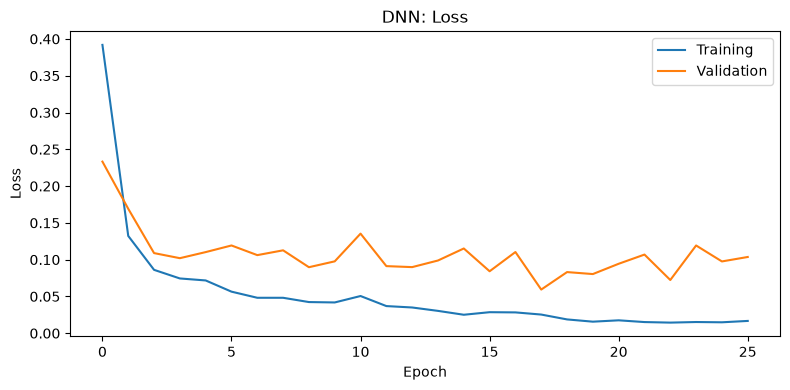

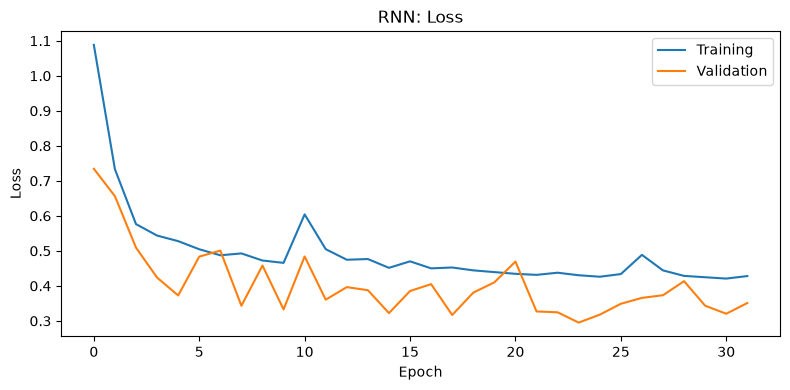

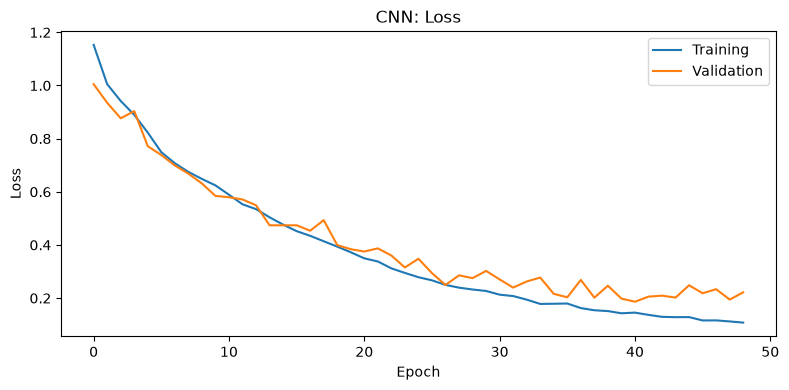

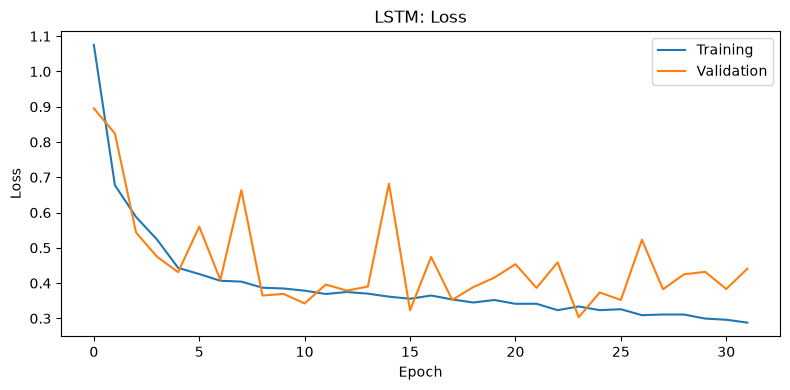

In [11]:
for name, result in training_results.items():
    history = result["history"]

    plt.figure(figsize=(8, 4))
    plt.plot(history["train_loss"], label="Training")
    plt.plot(history["val_loss"], label="Validation")
    plt.title(f"{name}: Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.tight_layout()
    plt.show()

#  Accuracy Curves

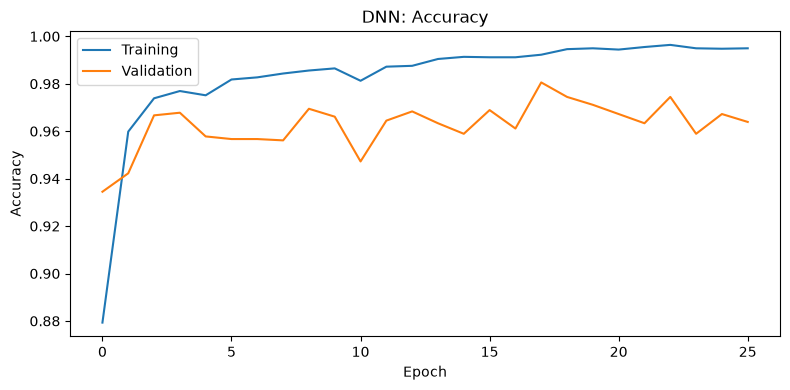

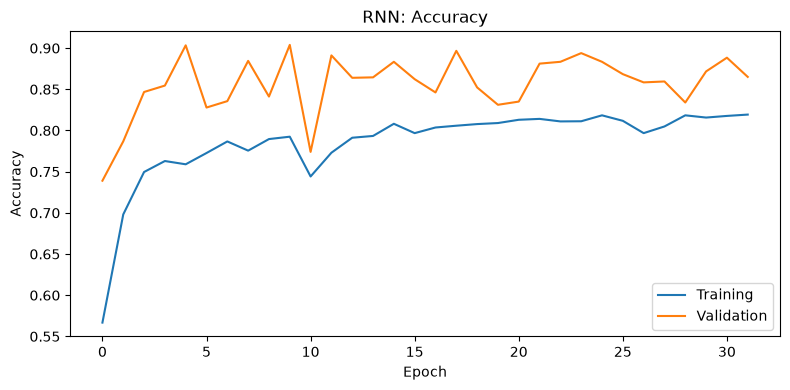

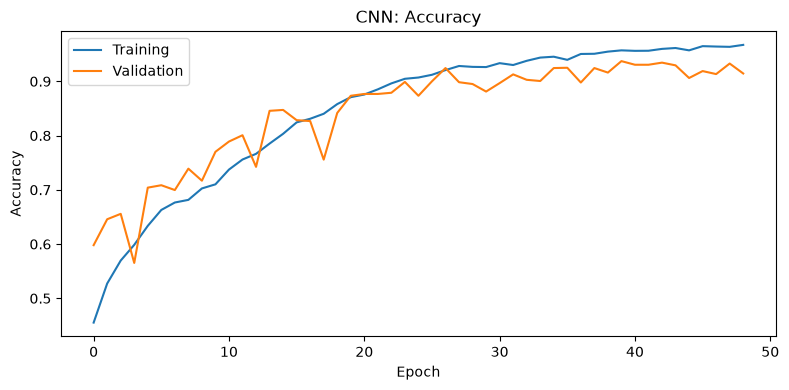

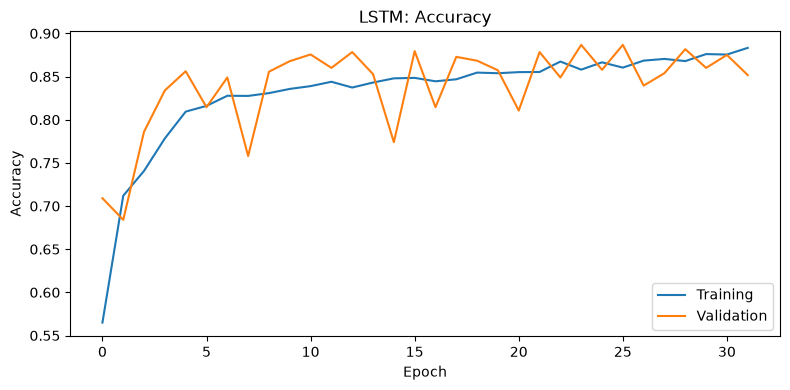

In [12]:
for name, result in training_results.items():
    history = result["history"]

    plt.figure(figsize=(8, 4))
    plt.plot(history["train_accuracy"], label="Training")
    plt.plot(history["val_accuracy"], label="Validation")
    plt.title(f"{name}: Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.tight_layout()
    plt.show()

### Training behavior analysis

For each architecture explain:

- convergence speed;
- overfitting;
- underfitting;
- stability;
- early stopping;
- train/validation gap.

**TODO:** Write add your analysis in ypur report.

# Final Test Evaluation



Report:

- Accuracy
- Macro Precision
- Macro Recall
- Macro F1
- Weighted F1
- Per-class metrics

In [13]:
test_results = {}

for name, model in trained_models.items():
    test_results[name] = evaluate_model(
        model,
        X_test,
        y_test,
    )

comparison_df = pd.DataFrame([
    {
        "Model": name,
        "Accuracy": result["accuracy"],
        "Macro Precision": result["macro_precision"],
        "Macro Recall": result["macro_recall"],
        "Macro F1": result["macro_f1"],
        "Weighted F1": result["weighted_f1"],
    }
    for name, result in test_results.items()
])

comparison_df

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
0,DNN,0.950458,0.952944,0.950837,0.951267,0.950711
1,RNN,0.770954,0.770378,0.764721,0.765938,0.773889
2,CNN,0.873431,0.880403,0.869207,0.870339,0.872651
3,LSTM,0.794028,0.795345,0.788760,0.786995,0.792477


# Per-Class Classification Reports

In [14]:
for name, result in test_results.items():
    print("\n" + "=" * 80)
    print(name)
    print("=" * 80)

    print(
        classification_report(
            y_test,
            result["predictions"],
            target_names=class_names,
            digits=4,
        )
    )


DNN
                    precision    recall  f1-score   support

            LAYING     1.0000    0.9646    0.9820       537
           SITTING     0.9452    0.8778    0.9102       491
          STANDING     0.8667    0.9530    0.9078       532
           WALKING     0.9717    0.9698    0.9707       496
WALKING_DOWNSTAIRS     0.9556    0.9738    0.9646       420
  WALKING_UPSTAIRS     0.9785    0.9660    0.9722       471

          accuracy                         0.9505      2947
         macro avg     0.9529    0.9508    0.9513      2947
      weighted avg     0.9523    0.9505    0.9507      2947


RNN
                    precision    recall  f1-score   support

            LAYING     1.0000    0.9516    0.9752       537
           SITTING     0.8533    0.7821    0.8162       491
          STANDING     0.8113    0.8402    0.8255       532
           WALKING     0.6653    0.6371    0.6509       496
WALKING_DOWNSTAIRS     0.5553    0.6810    0.6118       420
  WALKING_UPSTAIRS     0.7

# Confusion Matrices

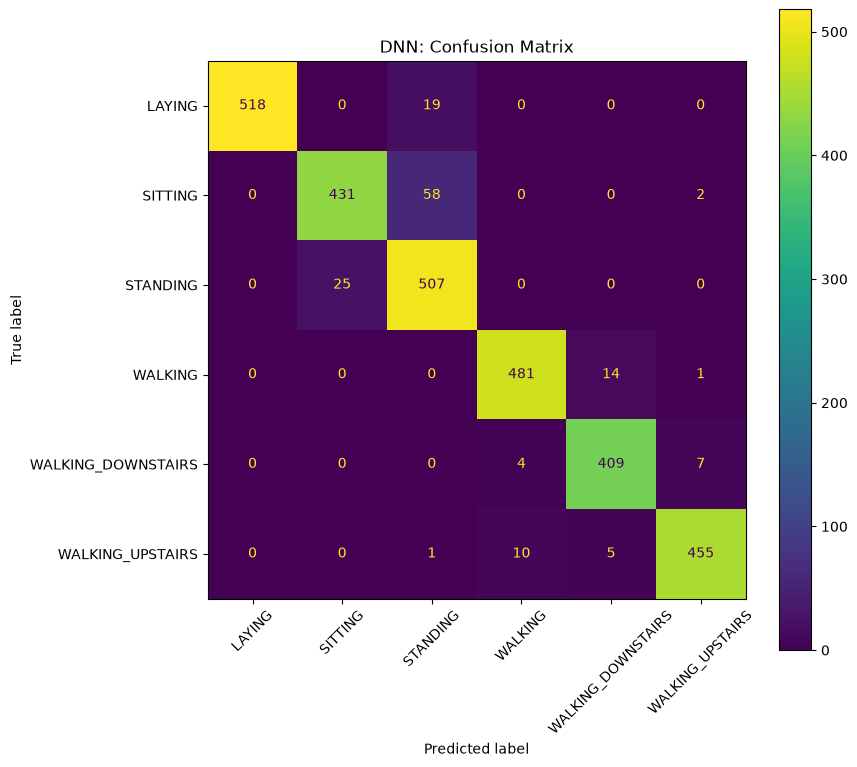

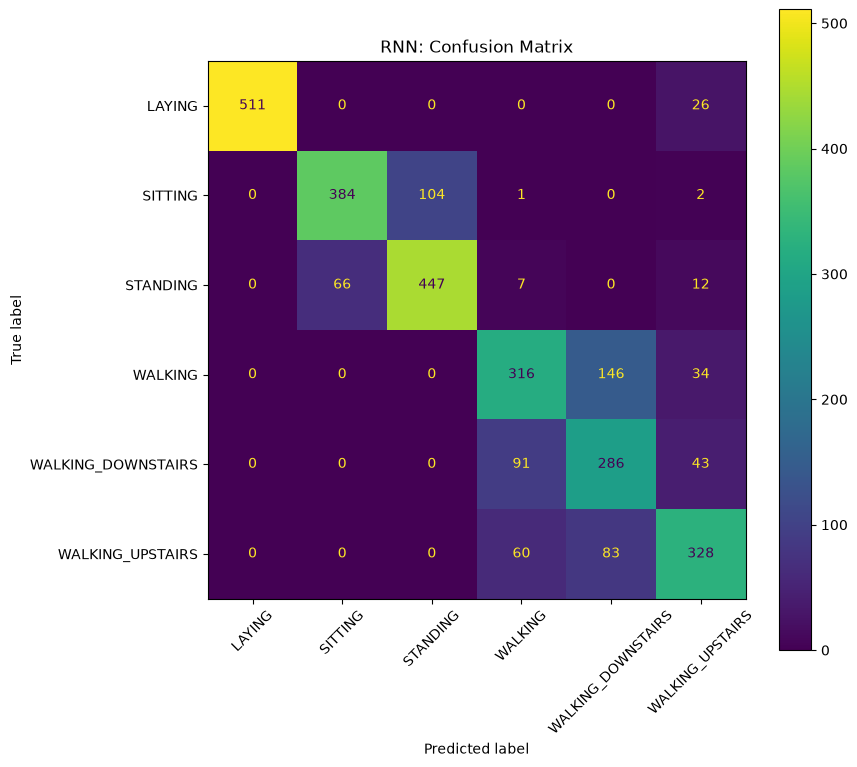

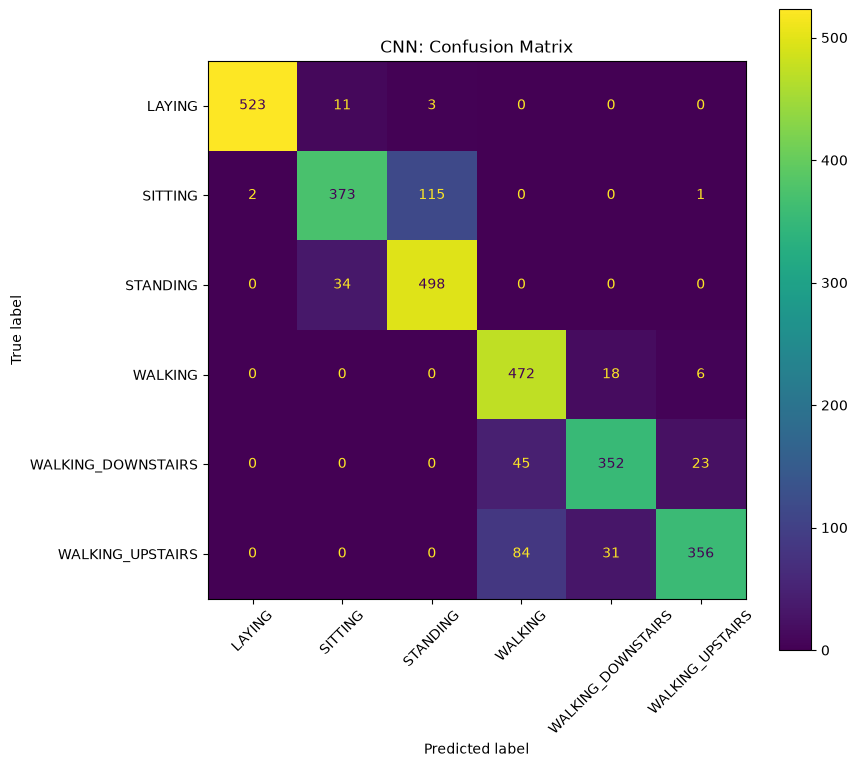

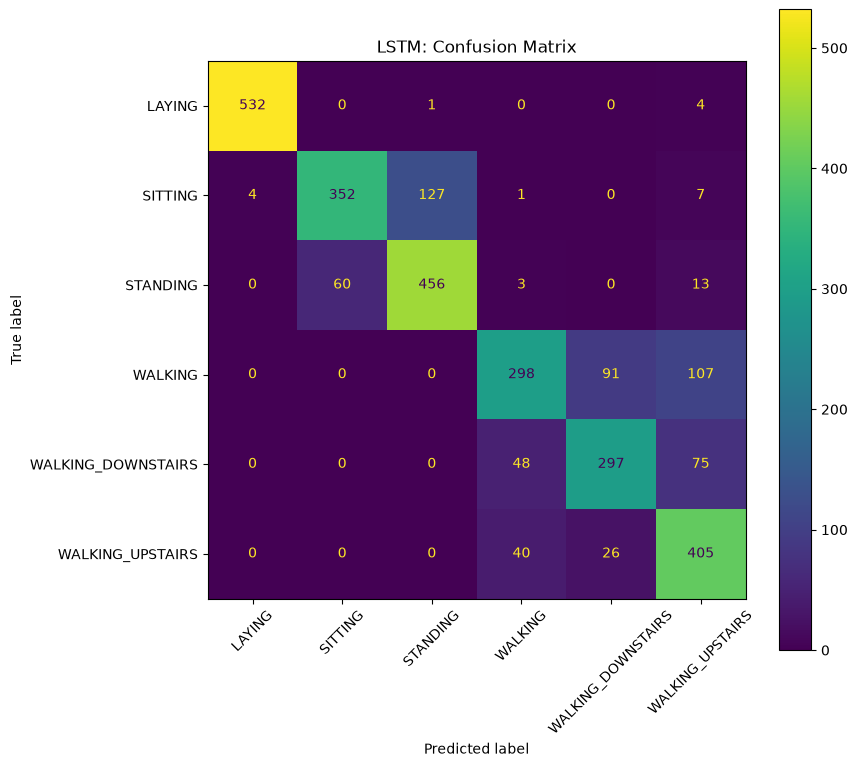

In [15]:
for name, result in test_results.items():
    cm = confusion_matrix(
        y_test,
        result["predictions"],
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_names,
    )

    fig, ax = plt.subplots(figsize=(9, 8))
    disp.plot(ax=ax, xticks_rotation=45)
    plt.title(f"{name}: Confusion Matrix")
    plt.tight_layout()
    plt.show()

### Activity-specific error analysis

Explain in ypur report:

- whether recurrent models make similar errors.
- whether CNN differs from RNN/LSTM.
- whether flattening disadvantages the DNN.


# Trainable Parameter Counts

In [16]:
parameter_counts = {
    name: count_parameters(model)
    for name, model in trained_models.items()
}

parameter_df = pd.DataFrame({
    "Model": list(parameter_counts.keys()),
    "Parameters": list(parameter_counts.values()),
})

parameter_df

,Model,Parameters
0,DNN,36486
1,RNN,4806
2,CNN,11078
3,LSTM,17670


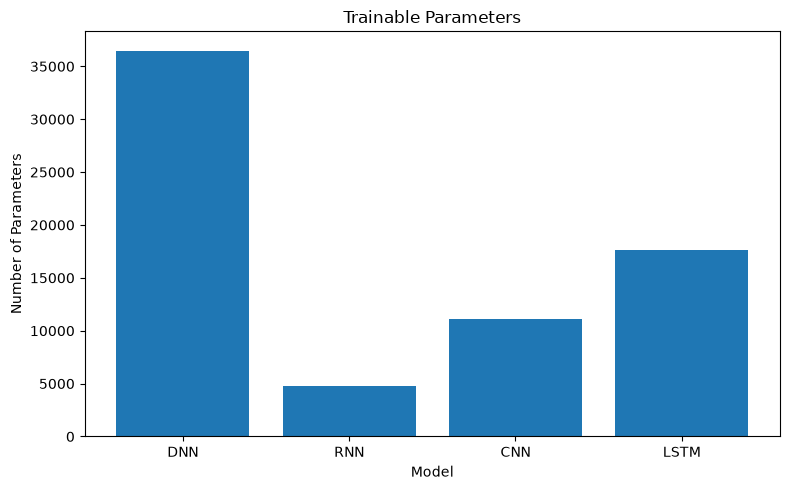

In [17]:
plt.figure(figsize=(8, 5))
plt.bar(parameter_df["Model"], parameter_df["Parameters"])
plt.title("Trainable Parameters")
plt.xlabel("Model")
plt.ylabel("Number of Parameters")
plt.tight_layout()
plt.show()

# Training-Time Comparison

In [18]:
training_time_df = pd.DataFrame([
    {
        "Model": name,
        "Training Time": result["training_time"],
        "Epochs": result["epochs_completed"],
        "Average Time / Epoch": (
            result["training_time"] /
            max(result["epochs_completed"], 1)
        ),
    }
    for name, result in training_results.items()
])

training_time_df

,Model,Training Time,Epochs,Average Time / Epoch
0,DNN,14.721075,26,0.566195
1,RNN,741.277308,32,23.164916
2,CNN,61.238980,49,1.249775
3,LSTM,159.735631,32,4.991738


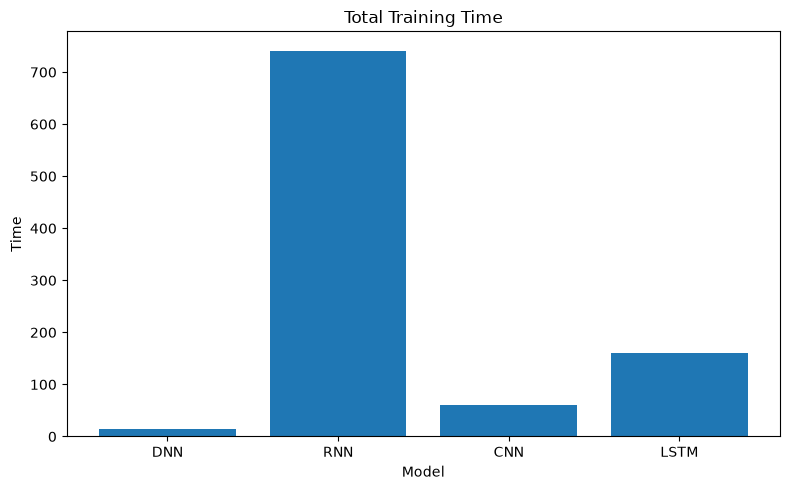

In [19]:
plt.figure(figsize=(8, 5))
plt.bar(
    training_time_df["Model"],
    training_time_df["Training Time"],
)
plt.title("Total Training Time")
plt.xlabel("Model")
plt.ylabel("Time")
plt.tight_layout()
plt.show()

# Inference-Time Comparison

In [20]:
inference_times = {
    name: measure_inference_time(model, X_test)
    for name, model in trained_models.items()
}

inference_df = pd.DataFrame({
    "Model": list(inference_times.keys()),
    "Inference Time": list(inference_times.values()),
})

inference_df

,Model,Inference Time
0,DNN,0.019191
1,RNN,1.207713
2,CNN,0.125329
3,LSTM,0.272004


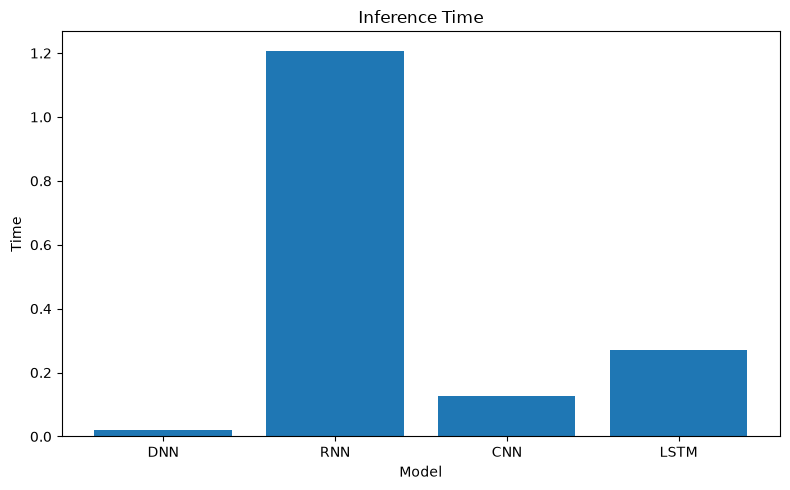

In [21]:
plt.figure(figsize=(8, 5))
plt.bar(
    inference_df["Model"],
    inference_df["Inference Time"],
)
plt.title("Inference Time")
plt.xlabel("Model")
plt.ylabel("Time")
plt.tight_layout()
plt.show()

# Complete Model Comparison

In [22]:
final_comparison = comparison_df.copy()

final_comparison["Parameters"] = (
    final_comparison["Model"].map(parameter_counts)
)

final_comparison["Training Time"] = (
    final_comparison["Model"].map({
        name: result["training_time"]
        for name, result in training_results.items()
    })
)

final_comparison["Inference Time"] = (
    final_comparison["Model"].map(inference_times)
)

final_comparison

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Parameters,Training Time,Inference Time
0,DNN,0.950458,0.952944,0.950837,0.951267,0.950711,36486,14.721075,0.019191
1,RNN,0.770954,0.770378,0.764721,0.765938,0.773889,4806,741.277308,1.207713
2,CNN,0.873431,0.880403,0.869207,0.870339,0.872651,11078,61.238980,0.125329
3,LSTM,0.794028,0.795345,0.788760,0.786995,0.792477,17670,159.735631,0.272004


# Predictive-Metric Comparison

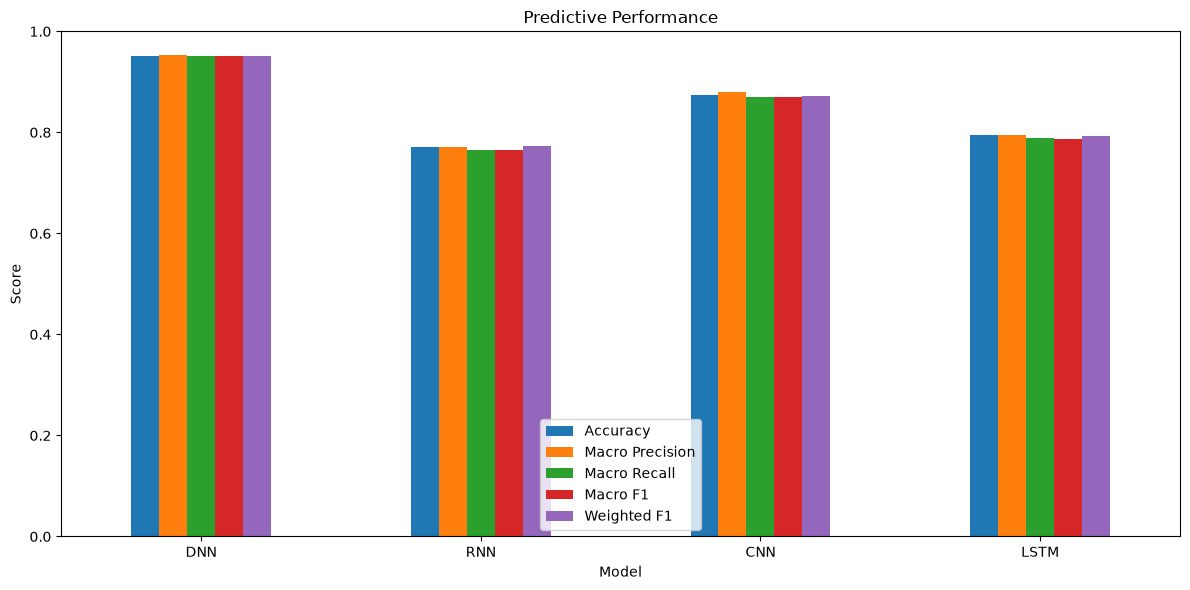

In [23]:
metric_columns = [
    "Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1",
    "Weighted F1",
]

final_comparison.set_index("Model")[metric_columns].plot(
    kind="bar",
    figsize=(12, 6),
)

plt.title("Predictive Performance")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Performance vs Computational Cost

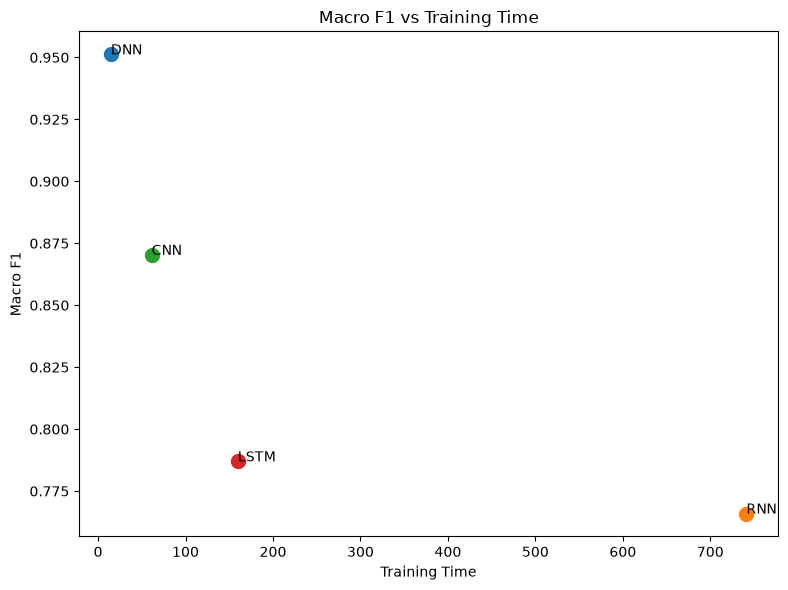

In [24]:
plt.figure(figsize=(8, 6))

for _, row in final_comparison.iterrows():
    plt.scatter(
        row["Training Time"],
        row["Macro F1"],
        s=100,
    )
    plt.annotate(
        row["Model"],
        (row["Training Time"], row["Macro F1"]),
    )

plt.xlabel("Training Time")
plt.ylabel("Macro F1")
plt.title("Macro F1 vs Training Time")
plt.tight_layout()
plt.show()

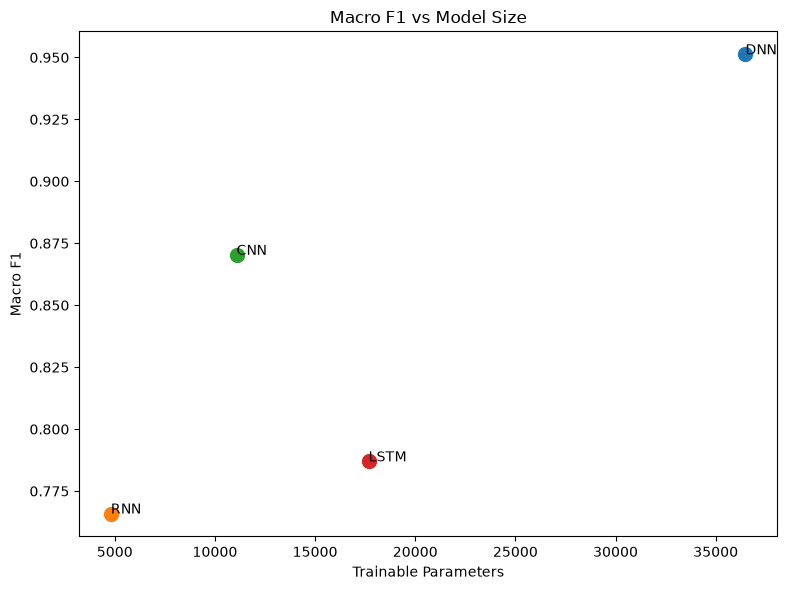

In [25]:
plt.figure(figsize=(8, 6))

for _, row in final_comparison.iterrows():
    plt.scatter(
        row["Parameters"],
        row["Macro F1"],
        s=100,
    )
    plt.annotate(
        row["Model"],
        (row["Parameters"], row["Macro F1"]),
    )

plt.xlabel("Trainable Parameters")
plt.ylabel("Macro F1")
plt.title("Macro F1 vs Model Size")
plt.tight_layout()
plt.show()

### Performance/cost discussion

Does increased architectural complexity produce a meaningful performance improvement relative to its computational cost?

**TODO:** Add your analysis in your report.

# Repeated Experiments: Three Random Seeds

Run the main comparison with at least:

```python
SEEDS = [1, 42, 123]
```

Instantiate a **new model** for every run.

Do not reuse previously trained weights.

In [ ]:
SEEDS = [1, 42, 123]

seed_experiment_results = []

for seed in SEEDS:
    set_seed(seed)

    # Fresh models for every seed (no reused weights)
    seed_models = {
        "DNN": DNNClassifier(
            sequence_length=sequence_length,
            n_features=n_features,
            n_classes=n_classes,
        ),
        "RNN": RNNClassifier(input_size=n_features, n_classes=n_classes),
        "CNN": CNNClassifier(input_size=n_features, n_classes=n_classes),
        "LSTM": LSTMClassifier(input_size=n_features, n_classes=n_classes),
    }

    # Same settings as before, only the seed changes
    config = {**TRAINING_CONFIG, "seed": seed}

    for name, model in seed_models.items():
        result = fit(model, X_train, y_train, X_val, y_val, **config)
        trained = result["model"]
        metrics = evaluate_model(trained, X_test, y_test)

        seed_experiment_results.append({
            "Seed": seed,
            "Model": name,
            "Accuracy": metrics["accuracy"],
            "Macro F1": metrics["macro_f1"],
            "Weighted F1": metrics["weighted_f1"],
            "Training Time": result["training_time"],
            "Parameters": count_parameters(trained),
        })


# Aggregate Repeated Runs

In [27]:
seed_df = pd.DataFrame(seed_experiment_results)
seed_df

""


In [28]:
if not seed_df.empty:
    seed_summary = (
        seed_df
        .groupby("Model")
        .agg({
            "Accuracy": ["mean", "std"],
            "Macro F1": ["mean", "std"],
            "Weighted F1": ["mean", "std"],
            "Training Time": ["mean", "std"],
        })
    )

    display(seed_summary)
else:
    print("Complete the repeated-seed experiment first.")

Complete the repeated-seed experiment first.


### Discuss


- variability across seeds.
- whether architecture comparisons remain consistent.
- whether a conclusion based on only one run would be reliable.

**TODO:** Enrich your report.

#  Hyperparameter Experiment

Perform at least one of the following experiment.

Examples:

- DNN hidden dimension or dropout;
- RNN hidden size;
- CNN kernel size;
- CNN filter count;
- LSTM hidden size;
- batch size;
- learning rate.

Change one factor and keep other important conditions fixed.

In [ ]:
# Selected hyperparameter: LSTM hidden size (everything else stays fixed)
experiment_values = [32, 64, 128, 256]
controlled_experiment_results = []

for value in experiment_values:
    set_seed(SEED)

    model = LSTMClassifier(
        input_size=n_features,
        n_classes=n_classes,
        hidden_size=value,
    )

    result = fit(model, X_train, y_train, X_val, y_val, **TRAINING_CONFIG)
    trained = result["model"]
    metrics = evaluate_model(trained, X_test, y_test)

    controlled_experiment_results.append({
        "Hidden Size": value,
        "Accuracy": metrics["accuracy"],
        "Macro F1": metrics["macro_f1"],
        "Weighted F1": metrics["weighted_f1"],
        "Training Time": result["training_time"],
        "Epochs": result["epochs_completed"],
        "Parameters": count_parameters(trained),
    })

controlled_df = pd.DataFrame(controlled_experiment_results)
controlled_df


### Controlled-experiment discussion

Explain:

- the parameter selected.
- why it was selected.
- effect on predictive performance.
- effect on computational cost.
- whether larger/more complex settings consistently improved generalization.

**TODO:** Make your report count!

# Save Experimental Results

In [ ]:
PROJECT_ROOT = Path.cwd()

metrics_dir = PROJECT_ROOT / "results" / "metrics"
figures_dir = PROJECT_ROOT / "results" / "figures"
models_dir = PROJECT_ROOT / "results" / "models"

metrics_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)
models_dir.mkdir(parents=True, exist_ok=True)

# Tables
final_comparison.to_csv(
    metrics_dir / "model_comparison.csv",
    index=False,
)

if "seed_df" in globals() and not seed_df.empty:
    seed_df.to_csv(
        metrics_dir / "seed_results.csv",
        index=False,
    )

if "controlled_df" in globals() and not controlled_df.empty:
    controlled_df.to_csv(
        metrics_dir / "controlled_experiment.csv",
        index=False,
    )

# Models: weights + history/timing for every trained model
for name, result in training_results.items():
    torch.save(result["model"].state_dict(), models_dir / f"{name}_weights.pt")

    info = {key: value for key, value in result.items() if key != "model"}
    with open(models_dir / f"{name}_result.json", "w") as f:
        json.dump(info, f)

# Figures: loss and accuracy curves
for name, result in training_results.items():
    history = result["history"]

    for metric, title in [("loss", "Loss"), ("accuracy", "Accuracy")]:
        plt.figure(figsize=(8, 4))
        plt.plot(history[f"train_{metric}"], label="Training")
        plt.plot(history[f"val_{metric}"], label="Validation")
        plt.title(f"{name}: {title}")
        plt.xlabel("Epoch")
        plt.ylabel(title)
        plt.legend()
        plt.tight_layout()
        plt.savefig(figures_dir / f"{name}_{metric}_curve.png", dpi=150)
        plt.close()

# Figures: confusion matrices
for name, result in test_results.items():
    cm = confusion_matrix(y_test, result["predictions"])
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)

    fig, ax = plt.subplots(figsize=(9, 8))
    disp.plot(ax=ax, xticks_rotation=45)
    plt.title(f"{name}: Confusion Matrix")
    plt.tight_layout()
    plt.savefig(figures_dir / f"{name}_confusion_matrix.png", dpi=150)
    plt.close()

# Figures: comparison bar charts
for column, title in [
    ("Parameters", "Trainable Parameters"),
    ("Training Time", "Total Training Time"),
    ("Inference Time", "Inference Time"),
]:
    plt.figure(figsize=(8, 5))
    plt.bar(final_comparison["Model"], final_comparison[column])
    plt.title(title)
    plt.xlabel("Model")
    plt.ylabel(column)
    plt.tight_layout()
    plt.savefig(figures_dir / f"{column.lower().replace(' ', '_')}.png", dpi=150)
    plt.close()

final_comparison.set_index("Model")[metric_columns].plot(kind="bar", figsize=(12, 6))
plt.title("Predictive Performance")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(figures_dir / "predictive_performance.png", dpi=150)
plt.close()

print("Saved to", PROJECT_ROOT / "results")
